In [1]:
#!pip install postcell

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
%cd /content/drive/MyDrive/2026/Markoding/Week-1-pi-integrasi-ai.git

!git status

/content/drive/MyDrive/2026/Markoding/Week-1-pi-integrasi-ai.git
On branch main
Your branch is ahead of 'origin/main' by 1 commit.
  (use "git push" to publish your local commits)

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	Computer Vision/Hands-on 3: Deteksi objek menggunakan YOLO.ipynb
	segudang-manfaat-bank-sampah-dan-cara-kerjanya-yang-perlu-diketahui (1).jpeg
	segudang-manfaat-bank-sampah-dan-cara-kerjanya-yang-perlu-diketahui.jpeg
	yolo26n.pt

nothing added to commit but untracked files present (use "git add" to track)


In [4]:
%reload_ext postcell
%postcell register

PostCell loaded
Loading config file from /content/drive/MyDrive/2026/Markoding/Week-1-pi-integrasi-ai.git/postcell.conf
Registered user Fara_Olivia at https://postcell.io/post_cell


In [5]:
!pip -q install -U ultralytics

In [6]:
%%postcell UnduhYOLO
from ultralytics import YOLO
# Mengunduh bobot pretrained jika belum tersedia
yolo_model = YOLO("yolo26n.pt")

print("Model YOLO berhasil dimuat.")

Cell posted for evaluation
Model YOLO berhasil dimuat.


Saving segudang-manfaat-bank-sampah-dan-cara-kerjanya-yang-perlu-diketahui.jpeg to segudang-manfaat-bank-sampah-dan-cara-kerjanya-yang-perlu-diketahui (2).jpeg


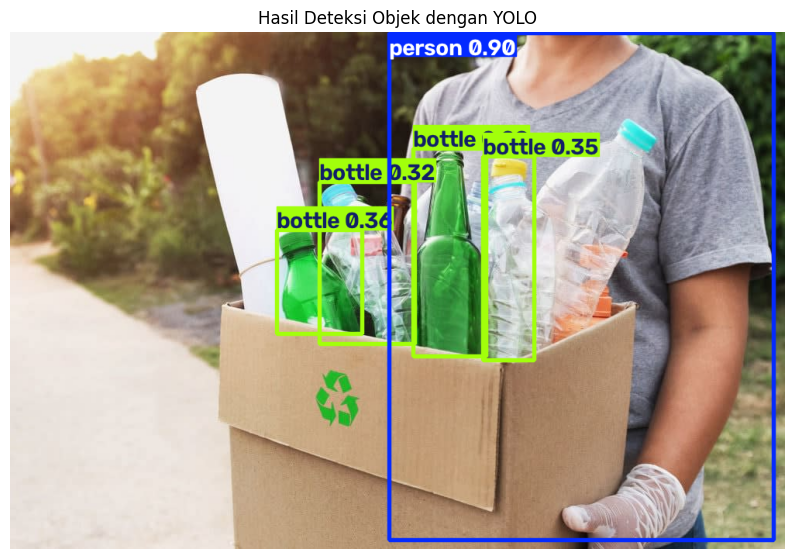

In [7]:
from google.colab import files
import cv2
import matplotlib.pyplot as plt

uploaded = files.upload()
yolo_filename = next(iter(uploaded))

results = yolo_model.predict(
    source=yolo_filename,
    conf=0.25,
    verbose=False
)

result = results[0]

# Ultralytics menyediakan hasil visualisasi dengan bounding box
annotated_bgr = result.plot()
annotated_rgb = cv2.cvtColor(
    annotated_bgr,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(10, 7))
plt.imshow(annotated_rgb)
plt.title("Hasil Deteksi Objek dengan YOLO")
plt.axis("off")
plt.show()

In [8]:
if result.boxes is None or len(result.boxes) == 0:
    print("Tidak ada objek yang terdeteksi.")
else:
    for box in result.boxes:
        class_id = int(box.cls[0].item())
        confidence = float(box.conf[0].item())
        x1, y1, x2, y2 = box.xyxy[0].tolist()

        label = yolo_model.names[class_id]

        print(f"Objek: {label}")
        print(f"Confidence: {confidence:.2%}")
        print(
            "Bounding box:",
            f"x1={x1:.0f}, y1={y1:.0f},",
            f"x2={x2:.0f}, y2={y2:.0f}"
        )
        print("-" * 40)

Objek: person
Confidence: 90.39%
Bounding box: x1=490, y1=1, x2=986, y2=655
----------------------------------------
Objek: bottle
Confidence: 35.97%
Bounding box: x1=345, y1=255, x2=455, y2=389
----------------------------------------
Objek: bottle
Confidence: 34.58%
Bounding box: x1=611, y1=161, x2=676, y2=424
----------------------------------------
Objek: bottle
Confidence: 31.93%
Bounding box: x1=400, y1=194, x2=522, y2=402
----------------------------------------
Objek: bottle
Confidence: 29.42%
Bounding box: x1=521, y1=150, x2=614, y2=419
----------------------------------------


Penjelasan:
- label: kategori objek yang dikenali model.
- confidence: skor keyakinan prediksi model.
- xyxy: koordinat kotak objek, yaitu sudut kiri atas dan kanan bawah.
Jika foto berisi tiga botol, model mungkin menghasilkan tiga kotak terpisah. Namun, hasil aktual tergantung kualitas foto, sudut pengambilan, ukuran objek, dan kemampuan model.

###Bagaimana jika kita ingin YOLO mendeteksi botol dan kaleng sampah secara khusus?
Model pretrained di atas hanya demonstrasi awal. Agar dapat mendeteksi kategori sampah sesuai kebutuhan proyek, kita harus melatih atau menyesuaikan model menggunakan dataset deteksi objek yang memiliki anotasi lokasi objek.
Salah satu pilihan adalah TACO (Trash Annotations in Context), yang menyediakan foto sampah di lingkungan nyata beserta anotasi objek. Dataset ini dapat dikonversi ke format YOLO, tetapi memerlukan persiapan dataset, pemetaan kelas, dan pemeriksaan anotasi terlebih dahulu



Contoh kode pelatihan YOLO setelah dataset disiapkan dalam format YOLO:

In [10]:
%%postcell finetuningyolo
from ultralytics import YOLO
import os

# Mulai dari bobot pretrained
model = YOLO("yolo26n.pt")

# Memeriksa apakah dataset kustom Anda ada di direktori
custom_data_path = "/content/waste-detection/data.yaml"

if os.path.exists(custom_data_path):
    # Gunakan dataset kustom jika sudah disiapkan
    dataset_to_use = custom_data_path
    print(f"Menggunakan dataset kustom: {dataset_to_use}")
else:
    # Sebagai demonstrasi (agar tidak error), kita gunakan dataset bawaan 'coco8.yaml'
    # yang akan otomatis diunduh oleh YOLO.
    dataset_to_use = "coco8.yaml"
    print(f"Dataset '{custom_data_path}' tidak ditemukan.\nMenggunakan dataset demo 'coco8.yaml' untuk demonstrasi latihan.")

results = model.train(
    data=dataset_to_use,
    epochs=3,      # Mengurangi epoch untuk demo agar cepat selesai
    imgsz=640,
    batch=8,
    patience=5
)

Cell posted for evaluation
Dataset '/content/waste-detection/data.yaml' tidak ditemukan.
Menggunakan dataset demo 'coco8.yaml' untuk demonstrasi latihan.
Ultralytics 8.4.176 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (AMD EPYC 7B12)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model

### Memahami Hasil Training YOLO

Pada tahap ini, kita berhasil menjalankan proses training menggunakan **YOLO26n**, yaitu varian YOLO berukuran nano yang relatif ringan. Model dimulai dari bobot pretrained, kemudian dilatih menggunakan dataset demonstrasi `COCO8`.

**1. Mengapa menggunakan COCO8?**

Sebelumnya, kita memeriksa apakah dataset khusus sampah tersedia di `/content/waste-detection/data.yaml`. Karena file tersebut belum ditemukan, program otomatis menggunakan `coco8.yaml`.

COCO8 merupakan dataset mini yang terdiri dari 4 gambar untuk training dan 4 gambar untuk validasi. Dataset ini digunakan untuk demonstrasi dan pengujian pipeline, bukan untuk membangun model deteksi sampah yang siap digunakan.

**2. Apa yang terjadi selama training?**

Model menjalani tiga epoch. Satu epoch berarti model menyelesaikan satu putaran melalui seluruh data training yang tersedia.

Karena COCO8 hanya memiliki empat gambar training, setiap epoch pada eksperimen ini hanya membutuhkan satu batch. Inilah sebabnya training selesai relatif cepat meskipun menggunakan CPU.

YOLO menggunakan bobot pretrained sebagai titik awal, lalu menyesuaikan parameter model berdasarkan anotasi objek pada dataset.

**3. Bagaimana membaca metrik evaluasi?**

Hasil validasi akhir menunjukkan:

- **Precision (P) = 0,552:** sekitar 55,2% prediksi positif model sesuai dengan objek yang benar menurut evaluasi ini.
- **Recall (R) = 0,963:** model menemukan sekitar 96,3% objek yang menjadi target evaluasi.
- **mAP50 = 0,943:** rata-rata average precision pada ambang IoU 0,50 mencapai 94,3%.
- **mAP50–95 = 0,697:** rata-rata mAP pada beberapa ambang IoU dari 0,50 hingga 0,95 mencapai 69,7%.

Precision dan recall mengukur aspek yang berbeda. Precision yang lebih rendah menunjukkan bahwa sebagian prediksi model masih dapat berupa deteksi yang keliru, sedangkan recall yang tinggi menunjukkan bahwa banyak objek pada data validasi berhasil ditemukan.

Namun, angka-angka tersebut berasal dari **hanya empat gambar validasi**. Hasil ini tidak cukup untuk menyimpulkan bahwa model memiliki performa tinggi pada foto nyata secara umum.

**4. Apa arti hasil per kelas?**

Pada tabel validasi, model menampilkan kelas seperti `person`, `dog`, `horse`, `elephant`, `umbrella`, dan `potted plant`.

Kelas-kelas ini berasal dari dataset COCO yang digunakan dalam demonstrasi. Artinya, model yang kita latih belum menjadi model khusus untuk mendeteksi botol plastik, kaleng, atau kategori sampah lainnya.

**5. Di mana model hasil training disimpan?**

YOLO menyimpan hasil eksperimen di:

- `/content/runs/detect/train-2/weights/best.pt` — bobot dengan hasil validasi terbaik selama training.
- `/content/runs/detect/train-2/weights/last.pt` — bobot pada akhir training.

Folder `runs/detect/train-2` juga berisi log dan visualisasi hasil training. File-file ini tersimpan di lingkungan runtime Colab dan dapat hilang ketika runtime dihapus, sehingga perlu diunduh atau disimpan ke Google Drive jika ingin digunakan kembali.

### Kesimpulan

Melalui eksperimen ini, kita telah menjalankan alur dasar object detection: memuat model pretrained, menyiapkan dataset beranotasi, melakukan training, dan mengevaluasi hasilnya.

Langkah berikutnya adalah menggunakan dataset yang memiliki anotasi bounding box untuk kelas sampah yang ingin dikenali. Dengan mengganti konfigurasi dataset dan melatih model menggunakan data tersebut, kita dapat mengembangkan demonstrasi ini menjadi sistem deteksi sampah yang lebih relevan dengan kebutuhan proyek.